# Downloads

In [ ]:
import pandas as pd
df = pd.read_csv("hf://datasets/hrshihab/BanFakeNews-2.0/All60Kdataset.csv")
df.to_csv('dataset.csv', index = False)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
! pip -q install nltk bangla-stemmer emoji wordcloud xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 17.3 MB/s eta 0:00:00


In [ ]:
! pip install -q --upgrade scikit-learn==1.5.2


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 87.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.9.post2 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


# Imports

In [ ]:
# Standard Library
import re
import string
from collections import Counter
import warnings

# Third-Party Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import emoji

# NLTK (Natural Language Toolkit)
import nltk
from nltk.corpus import stopwords

# Scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, RocCurveDisplay
)

# Bangla Language Processing Libraries
from bangla_stemmer.stemmer import stemmer

# Warnings Configuration
warnings.filterwarnings('ignore')


# Additional Setup

In [ ]:
# Downloading NLTK Bangla Module
try:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('bengali'))
except LookupError:
    stop_words = set()

# Initializing Bangla Stemmer
stemmer = stemmer.BanglaStemmer()
sns.set(style="whitegrid")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


# Loading Data

In [ ]:
df = pd.read_csv("dataset.csv")[['Content', 'Label']]
df.rename(columns = {'Content': 'text', 'Label': 'label'}, inplace = True)

In [ ]:
df.shape

(61581, 2)

There are 61,581 samples

In [ ]:
df.sample(20)

,text,label
16240,মিয়ানমারের টালবাহানার কারণে রোহিঙ্গাদের ফিরিয়ে...,1
45433,আন্তর্জাতিক ডেস্ক : ইন্টারপোলের সদ্য প্রাক্তন ...,1
6885,লিবিয়ার রাজধানী ত্রিপোলীতে বিদ্রোহীদের সঙ্গে ত...,1
12140,লন্ডনে সোমবার ‘দ্য বেস্ট ফিফা ফুটবল অ্যাওয়ার্ড...,1
61052,চট্টগ্রাম মতিনিধিপুটু মারামারি বাদ দিয়ে চট্টগ...,0
7243,‌জ্যেষ্ঠ প্র‌তি‌বেদক : আলাপ-আলোচনার মাধ্য‌মে ন...,1
24241,সিরাজগঞ্জ: সিরাজগঞ্জে ৪ হাজার পিস ইয়াবাসহ খোরশ...,1
51053,"গত ২৫ ডিসেম্বর ফেসবুকে একটি ভিডিওতে দেখা যায়, ...",0
29220,জাতীয় সংসদে কওমী শিক্ষার সর্বোচ্চস্তর দাওরায়ে...,1
39269,একটি আবাসিক স্কুলে ঢুকে ৩৪ জন মেয়ে শিক্ষার্থীক...,1


# Label Distribution

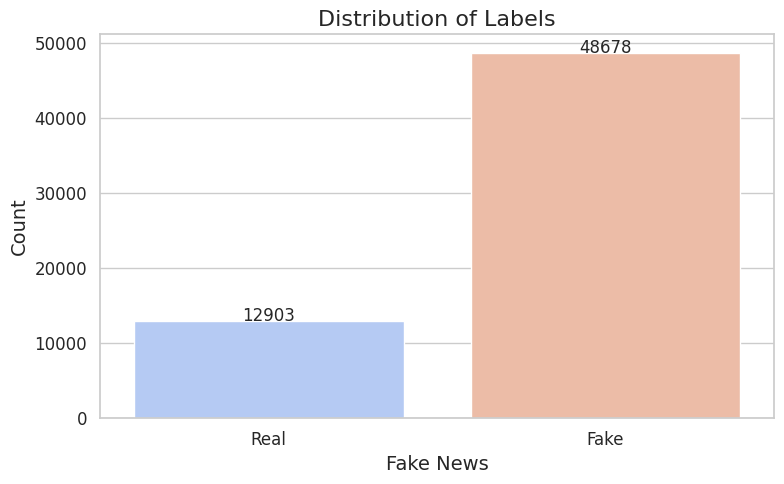

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', palette='coolwarm')

plt.title('Distribution of Labels', fontsize=16)
plt.xlabel('Fake News', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(ticks=[0, 1], labels=['Real', 'Fake'], fontsize=12)
plt.yticks(fontsize=12)

for p in plt.gca().patches:
    plt.text(p.get_x() + p.get_width() / 2, p.get_height() + 3,
             int(p.get_height()), ha='center', fontsize=12)
plt.tight_layout()
plt.show()

# Data Cleaning

### Data Cleaning Function

In [ ]:
def clean_data(df):
    # Remove all digits from the 'text' column
    df['text'] = df['text'].apply(lambda x: re.sub(r'\d+', '', str(x)))

    # Remove all English alphabet characters (both lowercase and uppercase)
    df['text'] = df['text'].apply(lambda x: re.sub(r'[a-zA-Z]', '', str(x)))

    # Remove all punctuation (including the Bengali punctuation '।')
    df['text'] = df['text'].apply(lambda x: x.translate(str.maketrans('', '', string.punctuation + '।')))

    # Remove all emojis from the text
    df['text'] = df['text'].apply(lambda x: emoji.replace_emoji(str(x), ''))

    # Remove stop words (words that are common and don't carry much meaning, defined in stop_words list)
    df['text'] = df['text'].apply(lambda x: ' '.join([word for word in str(x).split() if word not in stop_words]))

    # Replace multiple spaces with a single space and strip leading/trailing whitespace
    df['text'] = df['text'].apply(lambda x: re.sub(r'\s+', ' ', str(x)).strip())

    # Apply stemming to each word (reduce words to their root form)
    df['text'] = df['text'].apply(lambda x: ' '.join([stemmer.stem(word) for word in str(x).split()]))

    # Tokenize the cleaned text (split into list of words)
    df['tokens'] = df['text'].apply(lambda x: str(x).split())

    return df


### Run Data Cleaning Function

In [ ]:
df = clean_data(df)

Streaming output truncated to the last 5000 lines.
applied fourth rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied first rules..
applied second rules..
applied second rules..
applied fourth rules..
applied first rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth r

# Word Cloud

In [ ]:
!wget https://www.omicronlab.com/download/fonts/kalpurush.ttf

--2025-10-13 15:58:41--  https://www.omicronlab.com/download/fonts/kalpurush.ttf
Resolving www.omicronlab.com (www.omicronlab.com)... 104.21.12.234, 172.67.153.233, 2606:4700:3030::6815:cea, ...
Connecting to www.omicronlab.com (www.omicronlab.com)|104.21.12.234|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 314592 (307K) [application/octet-stream]
Saving to: ‘kalpurush.ttf’

kalpurush.ttf       100%[===================>] 307.22K  --.-KB/s    in 0.008s  

2025-10-13 15:58:41 (37.4 MB/s) - ‘kalpurush.ttf’ saved [314592/314592]



In [ ]:
def generate_bengali_wordcloud(df, font_path='bnfont1.otf', width=800, height=400, background_color='white'):
    words = [item for sublist in df['tokens'].values for item in sublist]

    fq = Counter(words)

    wordcloud = WordCloud(
        width=width,
        height=height,
        background_color=background_color,
        font_path=font_path
    ).generate_from_frequencies(fq)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.show()

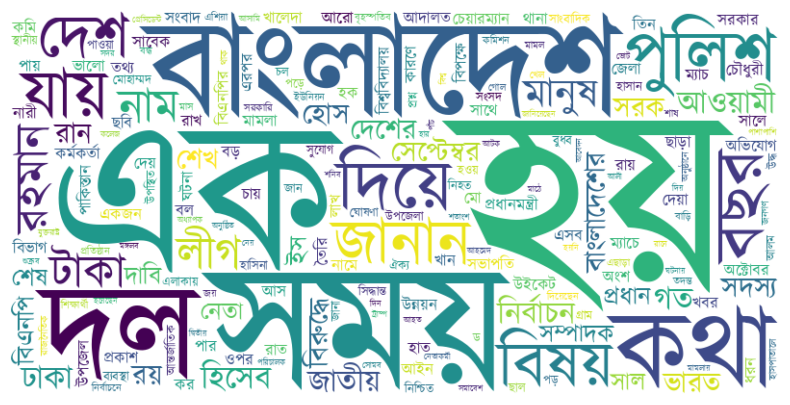

In [ ]:
generate_bengali_wordcloud(df, font_path = '/content/kalpurush.ttf')

# Vectorization

In [ ]:
# Applying TF-IDF Vectorization
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df['text']).toarray()
y = df['label']

# Smote

In [ ]:
from imblearn.over_sampling import SMOTE
# Applying SMOTE Oversampling method to balance the dataset
smote = SMOTE(sampling_strategy='auto', random_state=42)
X, y  = smote.fit_resample(X, y)

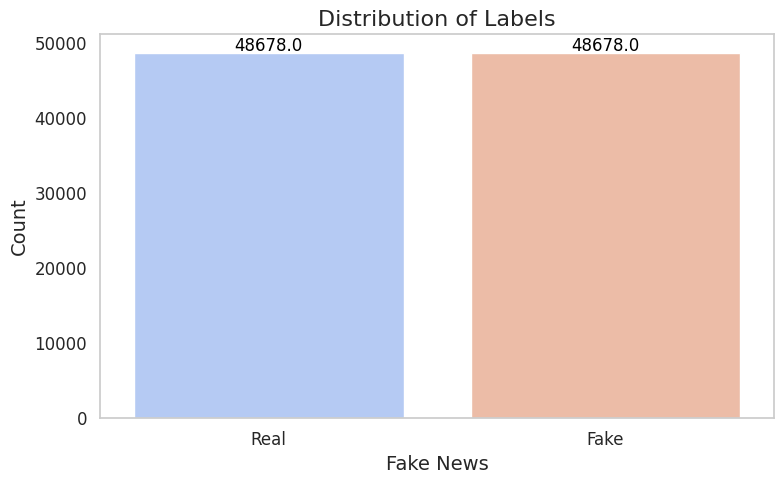

In [ ]:
# Label distribution after SMOTE
plt.figure(figsize=(8, 5))

label_counts = y.value_counts().reset_index()
label_counts.columns = ['label', 'count']

ax = sns.barplot(data=label_counts, x='label', y='count', palette='coolwarm')

plt.title('Distribution of Labels', fontsize=16)
plt.xlabel('Fake News', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(ticks=[0, 1], labels=['Real', 'Fake'], fontsize=12)
plt.yticks(fontsize=12)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height()}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center', fontsize=12, color='black', xytext=(0, 5),
        textcoords='offset points'
    )
plt.tight_layout()
plt.grid(False)
plt.show()

# Training Utils

In [ ]:
def train_with_K_fold(model_class, X, y, n_splits=5):
    # Using 5 K-Fold cross validation
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    # Arrays to store results
    accuracies, precisions, recalls, f1s, aucs = [], [], [], [], []
    cms = []

    all_fpr = np.linspace(0, 1, 100)
    tpr_list = []

    for i, (train_idx, test_idx) in enumerate(kf.split(X)):
        # Spliting Dataset
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # Initializing Model Class
        try:
          model = model_class(n_jobs = -1)
        except:
          model = model_class()

        # Training the model
        model.fit(X_train, y_train)

        # Predicting class and probabilities
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)[:, 1]

        # Measuring accuracy, precision, recall, f1
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_pred_proba)
        cm = confusion_matrix(y_test, y_pred)

        accuracies.append(acc)
        precisions.append(prec)
        recalls.append(rec)
        f1s.append(f1)
        aucs.append(auc)
        cms.append(cm)

        # ROC AUC Curve results
        roc_display = RocCurveDisplay.from_estimator(model, X_test, y_test, name=f"Fold {i+1}", alpha=0.3, lw=1)
        interp_tpr = np.interp(all_fpr, roc_display.fpr, roc_display.tpr)
        tpr_list.append(interp_tpr)

        print(f"Fold {i+1}/{n_splits}")
        print(f"Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1-Score: {f1:.4f}, AUC: {auc:.4f}")
        print(f"Confusion Matrix:\n{cm}\n")


    avg_acc = np.mean(accuracies)
    avg_prec = np.mean(precisions)
    avg_rec = np.mean(recalls)
    avg_f1 = np.mean(f1s)
    avg_auc = np.mean(aucs)
    total_cm = sum(cms)

    mean_tpr = np.mean(tpr_list, axis=0)

    return {
        "accuracy": avg_acc,
        "precision": avg_prec,
        "recall": avg_rec,
        "f1_score": avg_f1,
        "auc": avg_auc,
        "confusion_matrix": total_cm,
        "roc_data": {
            "fpr": all_fpr,
            "tpr": mean_tpr,
            "auc": avg_auc
        }
    }


In [ ]:
results_df = []

def append_results(metrics, model):
    results_df.append({
        "Model": model,
        "Accuracy": metrics["accuracy"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1": metrics["f1_score"],
        "AUC": metrics["auc"]
    })
    print(results_df[-1])




def plot_confusion_matrix(cm, model_name):

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels,
        cbar=False, annot_kws={"size": 14}
    )
    plt.title(f"Confusion Matrix of {model_name}", fontsize=16, pad=20)
    plt.xlabel("Predicted", fontsize=14)
    plt.ylabel("Actual", fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12, rotation=0)
    plt.tight_layout()
    plt.show()
labels = ['Real', 'Fake']

def plot_roc_curve(roc_data, model_name):

  plt.figure(figsize=(10, 6))
  plt.plot(roc_data["fpr"], roc_data["tpr"], color='b', label=f"Mean ROC (AUC = {roc_data['auc']:.2f})", lw=2)
  plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
  plt.title(f"ROC Curve of {model_name}")
  plt.xlabel("False Positive Rate")
  plt.ylabel("True Positive Rate")
  plt.legend(loc="lower right")
  plt.grid(alpha=0.3)
  plt.show()

# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

## Training

Fold 1/5
Accuracy: 0.8988, Precision: 0.8800, Recall: 0.9250, F1-Score: 0.9020, AUC: 0.9488
Confusion Matrix:
[[8435 1236]
 [ 735 9066]]

Fold 2/5
Accuracy: 0.9022, Precision: 0.8857, Recall: 0.9227, F1-Score: 0.9038, AUC: 0.9536
Confusion Matrix:
[[8619 1155]
 [ 750 8947]]

Fold 3/5
Accuracy: 0.9003, Precision: 0.8824, Recall: 0.9230, F1-Score: 0.9022, AUC: 0.9493
Confusion Matrix:
[[8569 1194]
 [ 748 8960]]

Fold 4/5
Accuracy: 0.8988, Precision: 0.8781, Recall: 0.9248, F1-Score: 0.9009, AUC: 0.9477
Confusion Matrix:
[[8542 1243]
 [ 728 8958]]

Fold 5/5
Accuracy: 0.8998, Precision: 0.8823, Recall: 0.9239, F1-Score: 0.9026, AUC: 0.9498
Confusion Matrix:
[[8479 1206]
 [ 745 9041]]



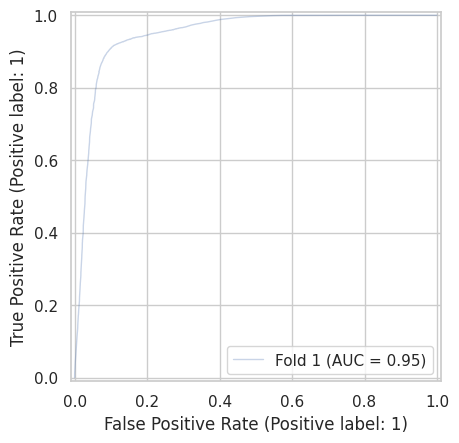

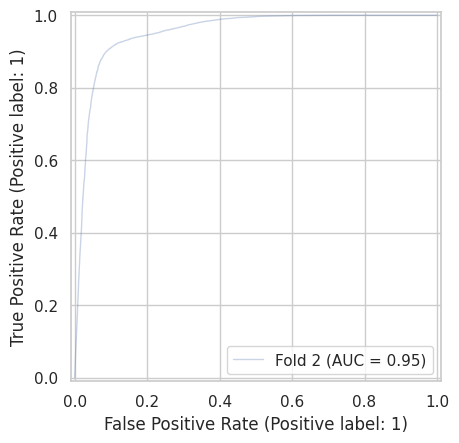

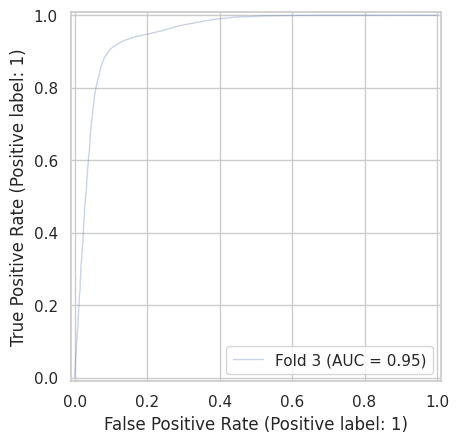

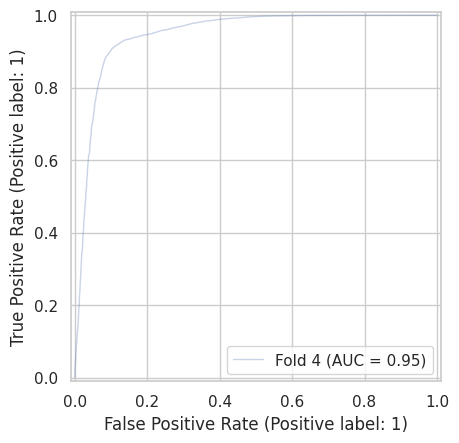

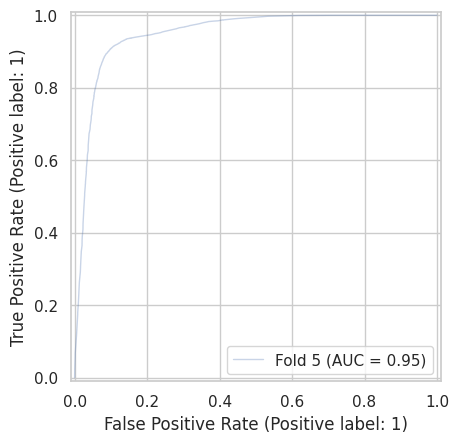

In [ ]:
metrics = train_with_K_fold(RandomForestClassifier, X, y)

## Metrics

In [ ]:
append_results(metrics, 'Random Forest')

{'Model': 'Random Forest', 'Accuracy': np.float64(0.8999548171359238), 'Precision': np.float64(0.8817113182936597), 'Recall': np.float64(0.9238650198599551), 'F1': np.float64(0.9022928054825593), 'AUC': np.float64(0.9498265657488201)}


## ROC Curve

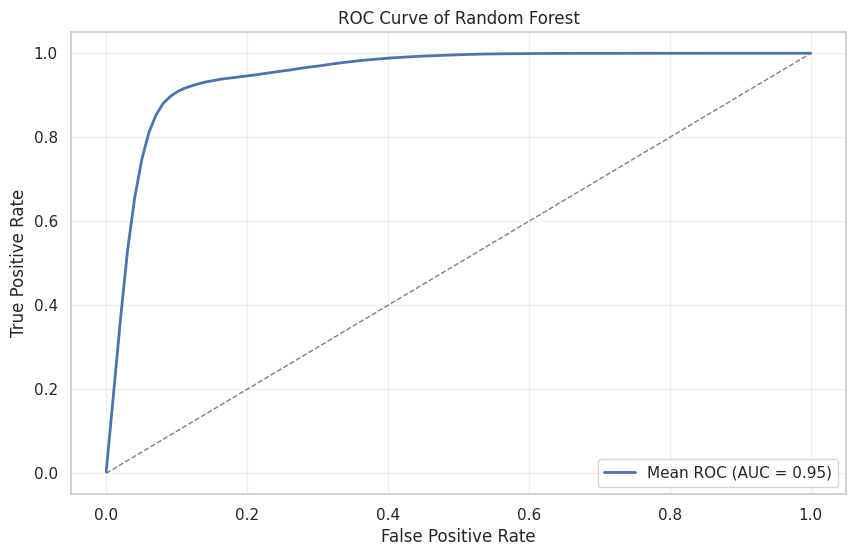

In [ ]:
plot_roc_curve(metrics["roc_data"], "Random Forest")

## Confusion Matrix

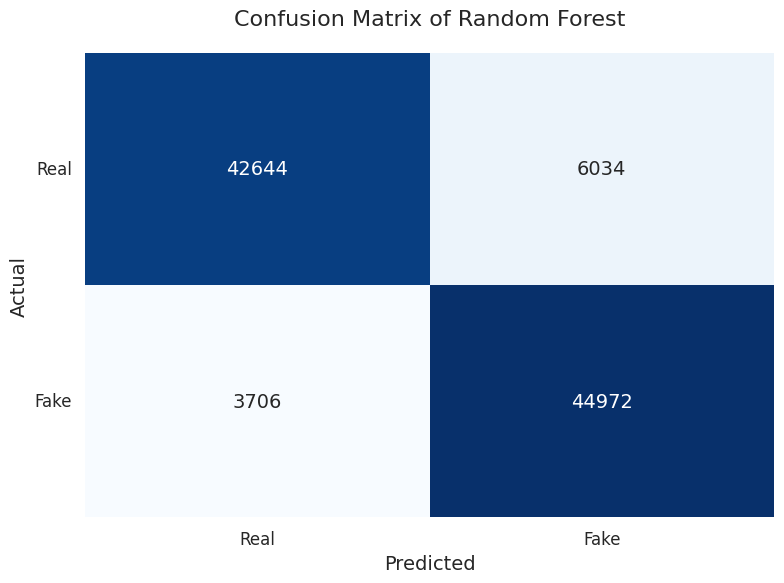

In [ ]:
plot_confusion_matrix(metrics['confusion_matrix'], "Random Forest")

# LightGBM

In [ ]:
from lightgbm import LGBMClassifier

## Training

[LightGBM] [Info] Number of positive: 38877, number of negative: 39007
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.161998 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 440991
[LightGBM] [Info] Number of data points in the train set: 77884, number of used features: 4729
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499165 -> initscore=-0.003338
[LightGBM] [Info] Start training from score -0.003338
Fold 1/5
Accuracy: 0.8808, Precision: 0.8520, Recall: 0.9235, F1-Score: 0.8863, AUC: 0.9511
Confusion Matrix:
[[8099 1572]
 [ 750 9051]]

[LightGBM] [Info] Number of positive: 38981, number of negative: 38904
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.038702 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[Li

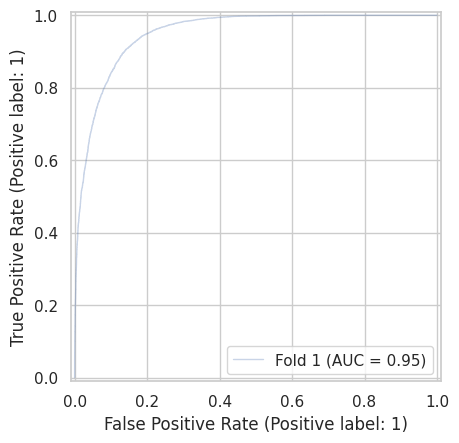

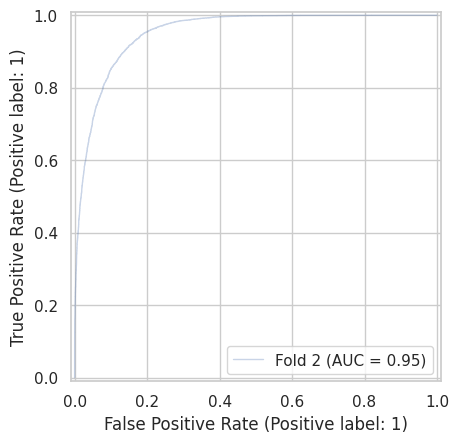

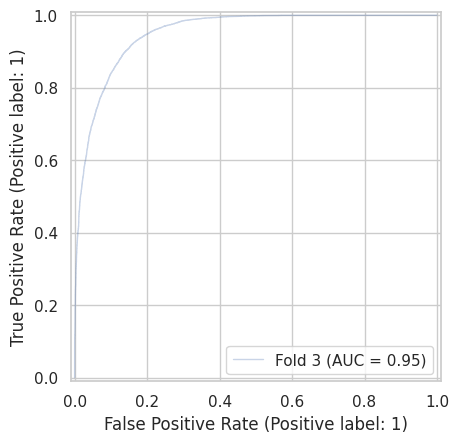

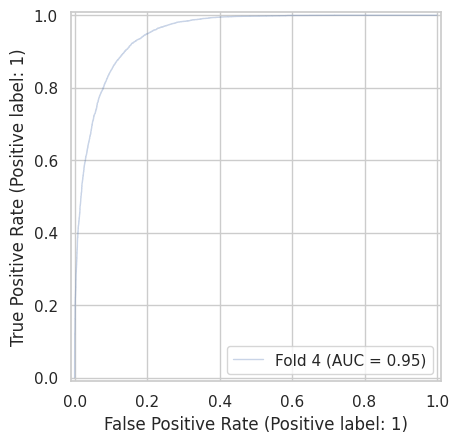

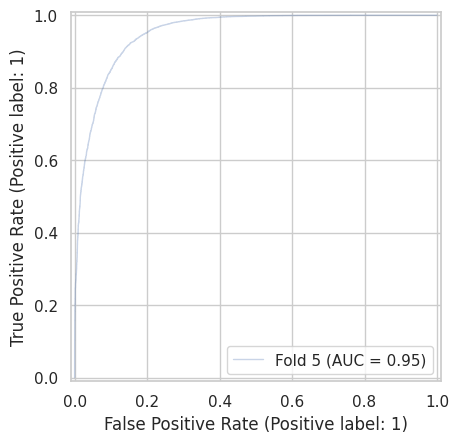

In [ ]:
metrics = train_with_K_fold(LGBMClassifier, X, y)

## Metrics

In [ ]:
append_results(metrics, 'LightGBM')

{'Model': 'LightGBM', 'Accuracy': np.float64(0.8814762390031451), 'Precision': np.float64(0.8506676730618781), 'Recall': np.float64(0.9254135781248264), 'F1': np.float64(0.8864618435516485), 'AUC': np.float64(0.9520669460207978)}


## ROC Curve

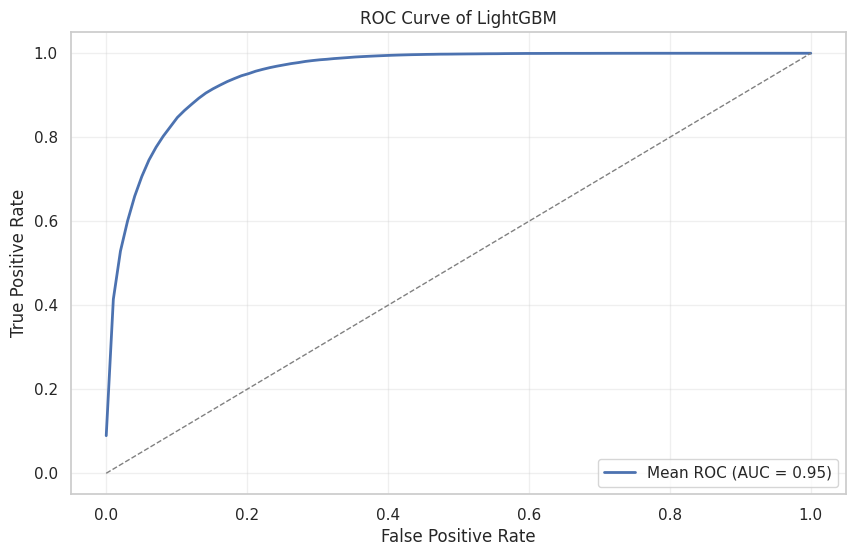

In [ ]:
plot_roc_curve(metrics["roc_data"], "LightGBM")

## Confusion Matrix

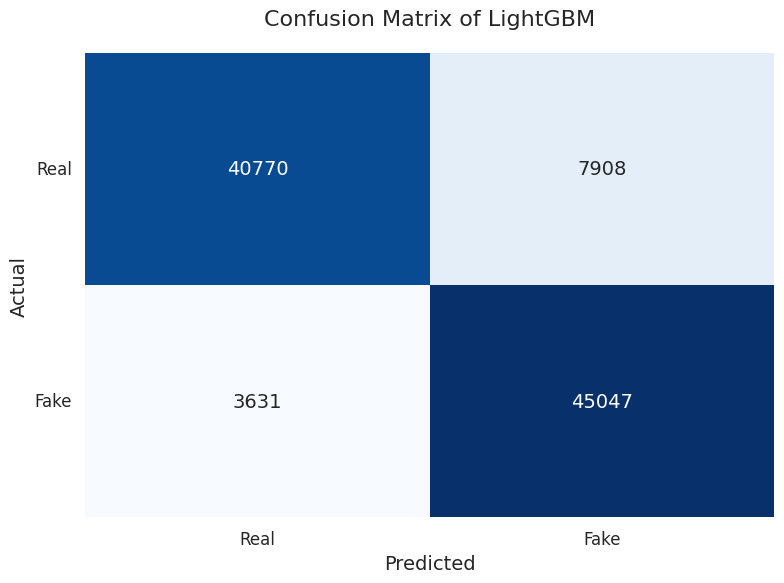

In [ ]:
plot_confusion_matrix(metrics['confusion_matrix'], "LightGBM")

# XGBoost

In [ ]:
from xgboost import XGBClassifier

## Training

Fold 1/5
Accuracy: 0.8846, Precision: 0.8635, Recall: 0.9153, F1-Score: 0.8887, AUC: 0.9557
Confusion Matrix:
[[8253 1418]
 [ 830 8971]]

Fold 2/5
Accuracy: 0.8891, Precision: 0.8663, Recall: 0.9193, F1-Score: 0.8920, AUC: 0.9585
Confusion Matrix:
[[8398 1376]
 [ 783 8914]]

Fold 3/5
Accuracy: 0.8874, Precision: 0.8679, Recall: 0.9133, F1-Score: 0.8900, AUC: 0.9566
Confusion Matrix:
[[8413 1350]
 [ 842 8866]]

Fold 4/5
Accuracy: 0.8882, Precision: 0.8670, Recall: 0.9157, F1-Score: 0.8907, AUC: 0.9569
Confusion Matrix:
[[8425 1360]
 [ 817 8869]]

Fold 5/5
Accuracy: 0.8865, Precision: 0.8662, Recall: 0.9156, F1-Score: 0.8902, AUC: 0.9570
Confusion Matrix:
[[8301 1384]
 [ 826 8960]]



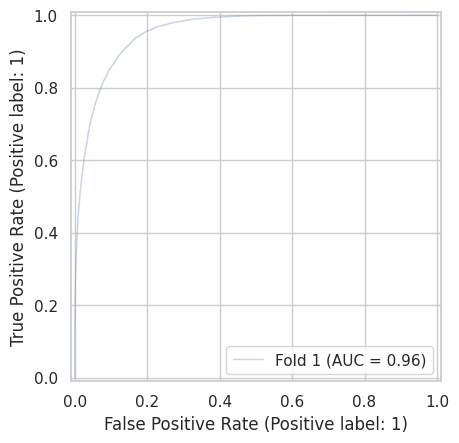

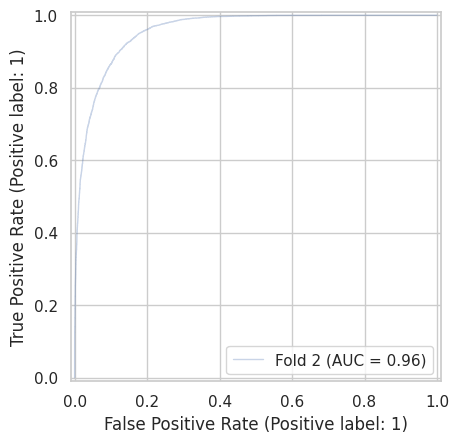

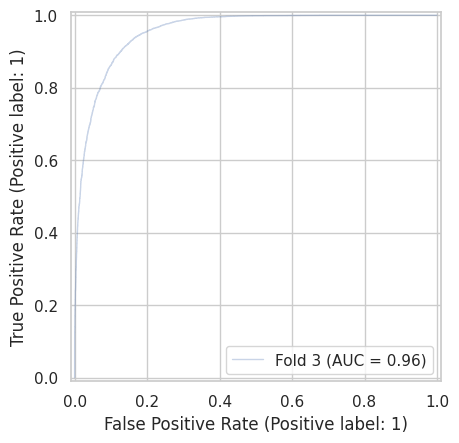

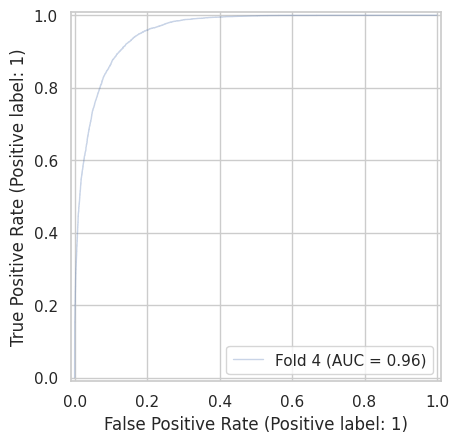

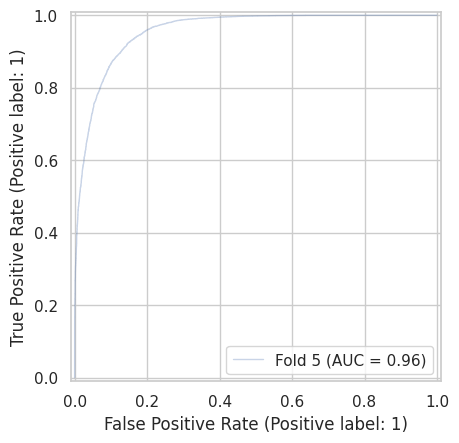

In [ ]:
metrics = train_with_K_fold(XGBClassifier, X, y)

## Metrics

In [ ]:
append_results(metrics, 'XGBoost')

{'Model': 'XGBoost', 'Accuracy': np.float64(0.8871564423791538), 'Precision': np.float64(0.8661778146991568), 'Recall': np.float64(0.9158161420916777), 'F1': np.float64(0.8903036988185937), 'AUC': np.float64(0.9569461601210041)}


## ROC Curve

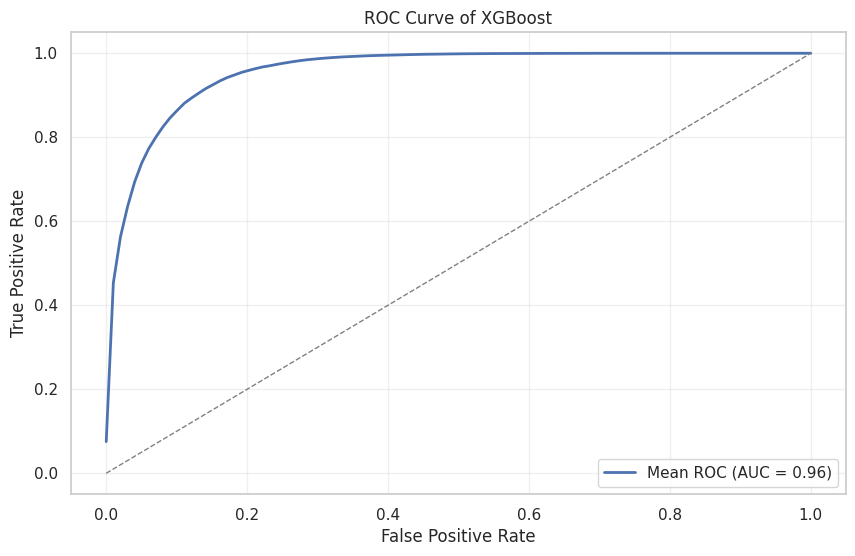

In [ ]:
plot_roc_curve(metrics["roc_data"], "XGBoost")

## Confusion Matrix

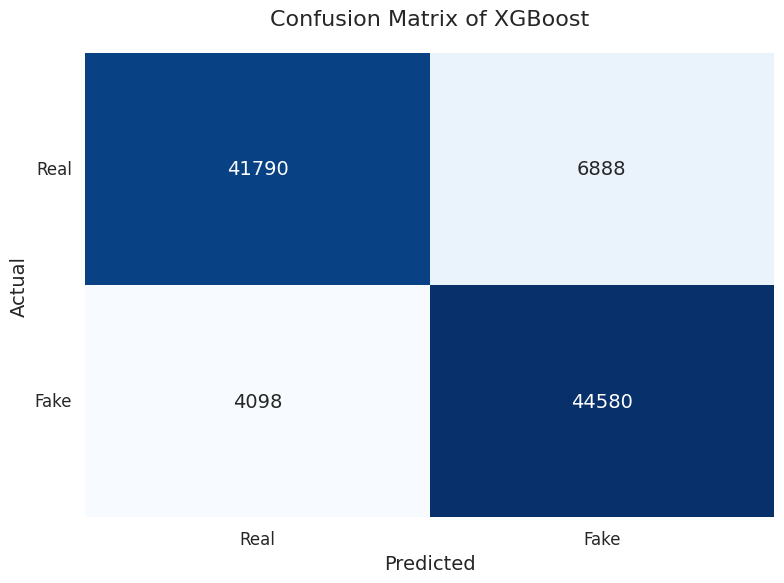

In [ ]:
plot_confusion_matrix(metrics['confusion_matrix'], "XGBoost")

# CatBoost

In [ ]:
!pip install catboost -q
from catboost import CatBoostClassifier

## Training

Streaming output truncated to the last 5000 lines.
34:	learn: 0.4522444	total: 6.63s	remaining: 3m 2s
35:	learn: 0.4499404	total: 6.79s	remaining: 3m 1s
36:	learn: 0.4480106	total: 6.96s	remaining: 3m 1s
37:	learn: 0.4464461	total: 7.13s	remaining: 3m
38:	learn: 0.4447418	total: 7.29s	remaining: 2m 59s
39:	learn: 0.4431735	total: 7.46s	remaining: 2m 58s
40:	learn: 0.4418305	total: 7.62s	remaining: 2m 58s
41:	learn: 0.4401188	total: 7.79s	remaining: 2m 57s
42:	learn: 0.4377288	total: 7.95s	remaining: 2m 56s
43:	learn: 0.4360014	total: 8.12s	remaining: 2m 56s
44:	learn: 0.4339388	total: 8.31s	remaining: 2m 56s
45:	learn: 0.4325742	total: 8.48s	remaining: 2m 55s
46:	learn: 0.4310600	total: 8.65s	remaining: 2m 55s
47:	learn: 0.4297374	total: 8.84s	remaining: 2m 55s
48:	learn: 0.4285376	total: 9.01s	remaining: 2m 54s
49:	learn: 0.4272904	total: 9.18s	remaining: 2m 54s
50:	learn: 0.4258790	total: 9.34s	remaining: 2m 53s
51:	learn: 0.4244524	total: 9.53s	remaining: 2m 53s
52:	learn: 0.4231882

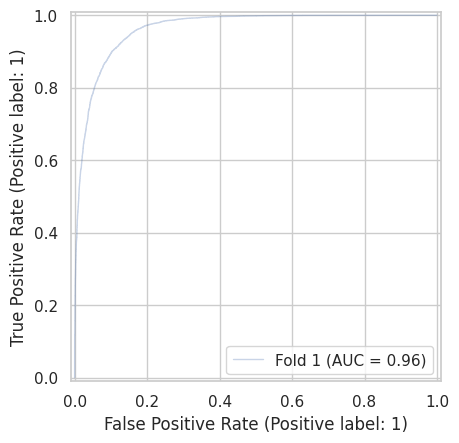

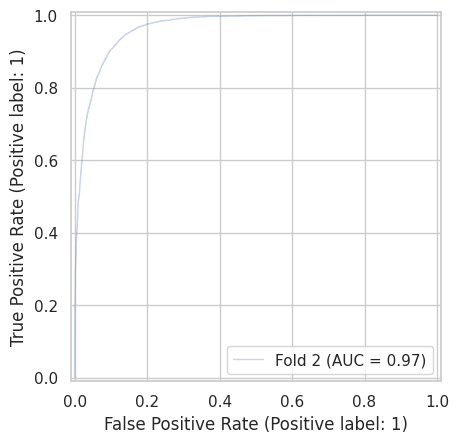

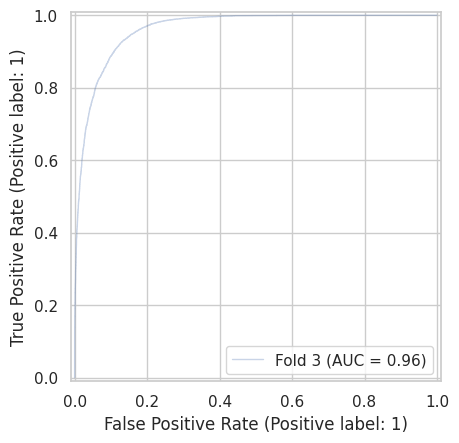

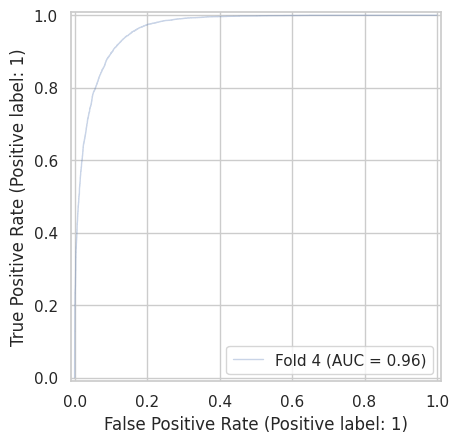

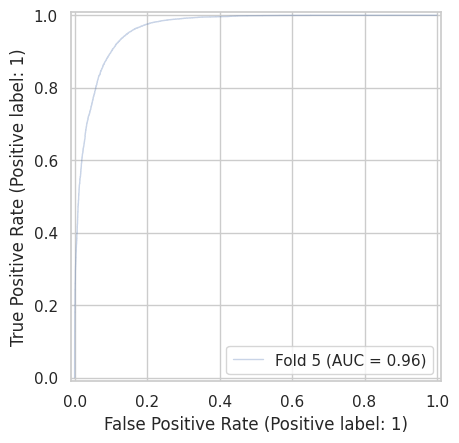

In [ ]:
metrics = train_with_K_fold(CatBoostClassifier, X, y)

## Metrics

In [ ]:
append_results(metrics, 'CatBoost')

{'Model': 'CatBoost', 'Accuracy': np.float64(0.9006327515834075), 'Precision': np.float64(0.8799129950461244), 'Recall': np.float64(0.9278942828457357), 'F1': np.float64(0.9032654658912825), 'AUC': np.float64(0.9641365109780539)}


## ROC Curve

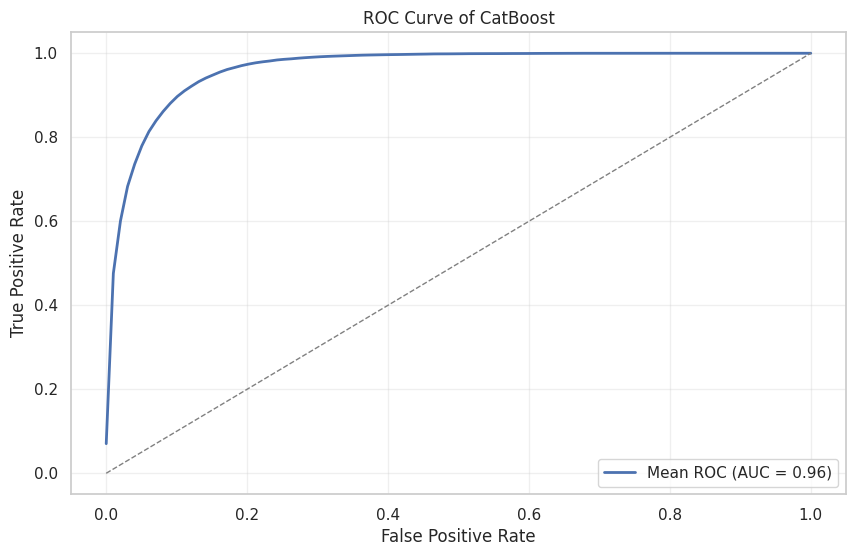

In [ ]:
plot_roc_curve(metrics["roc_data"], 'CatBoost')

## Confusion Matrix

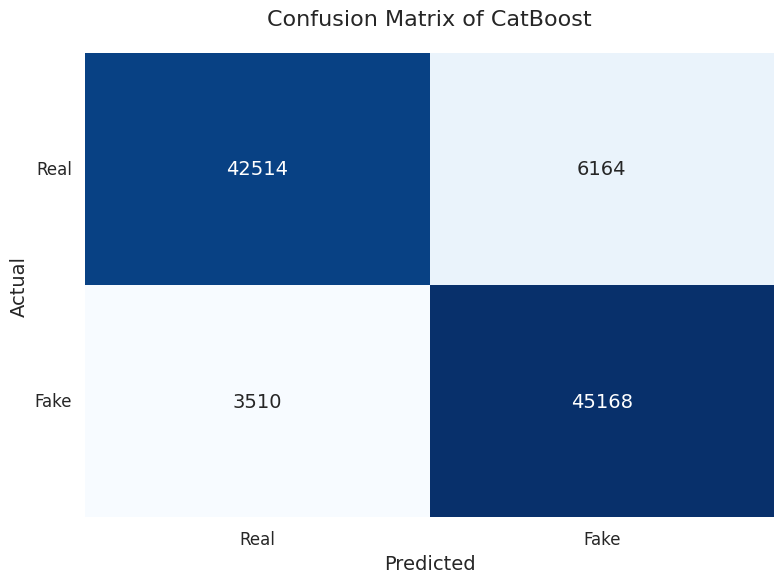

In [ ]:
plot_confusion_matrix(metrics['confusion_matrix'], 'CatBoost')

# Naive Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB

## Training

Fold 1/5
Accuracy: 0.8025, Precision: 0.7594, Recall: 0.8894, F1-Score: 0.8193, AUC: 0.8818
Confusion Matrix:
[[6909 2762]
 [1084 8717]]

Fold 2/5
Accuracy: 0.8001, Precision: 0.7537, Recall: 0.8892, F1-Score: 0.8159, AUC: 0.8812
Confusion Matrix:
[[6956 2818]
 [1074 8623]]

Fold 3/5
Accuracy: 0.7962, Precision: 0.7512, Recall: 0.8838, F1-Score: 0.8122, AUC: 0.8751
Confusion Matrix:
[[6922 2841]
 [1128 8580]]

Fold 4/5
Accuracy: 0.8009, Precision: 0.7542, Recall: 0.8898, F1-Score: 0.8164, AUC: 0.8782
Confusion Matrix:
[[6976 2809]
 [1067 8619]]

Fold 5/5
Accuracy: 0.8073, Precision: 0.7638, Recall: 0.8925, F1-Score: 0.8231, AUC: 0.8820
Confusion Matrix:
[[6984 2701]
 [1052 8734]]



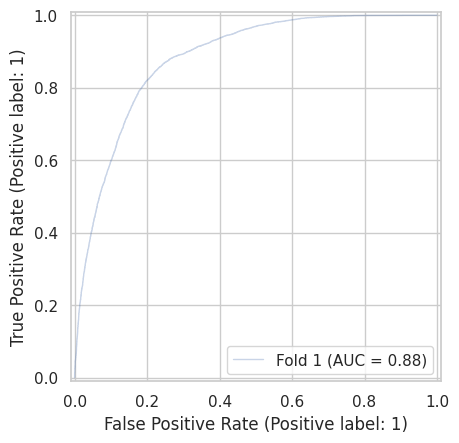

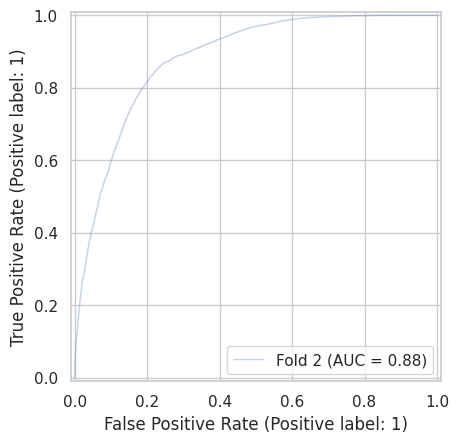

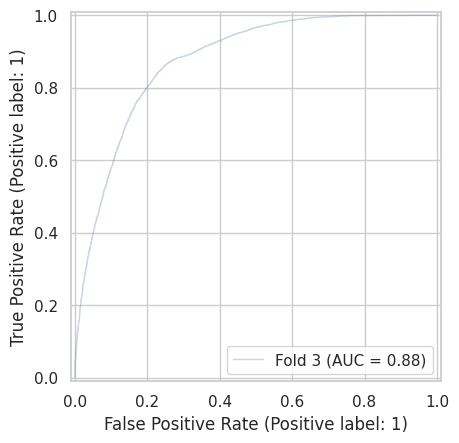

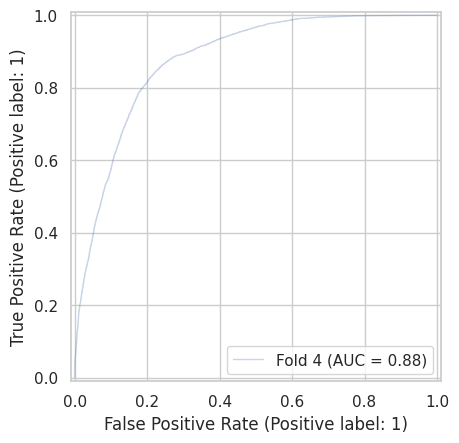

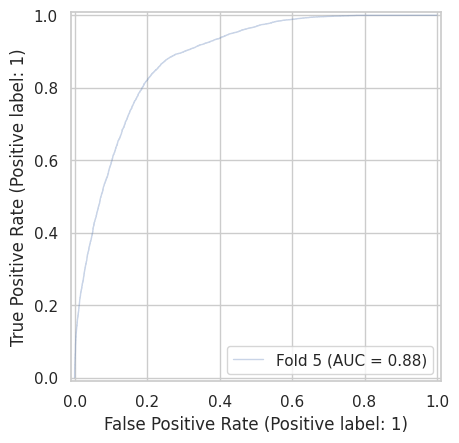

In [ ]:
metrics = train_with_K_fold(MultinomialNB, X, y)

## Metrics

In [ ]:
append_results(metrics, 'Naive Bayes')

{'Model': 'Naive Bayes', 'Accuracy': np.float64(0.801388706428839), 'Precision': np.float64(0.7564645683789666), 'Recall': np.float64(0.8889581606154335), 'F1': np.float64(0.8173738905721949), 'AUC': np.float64(0.8796622827430784)}


## ROC Curve

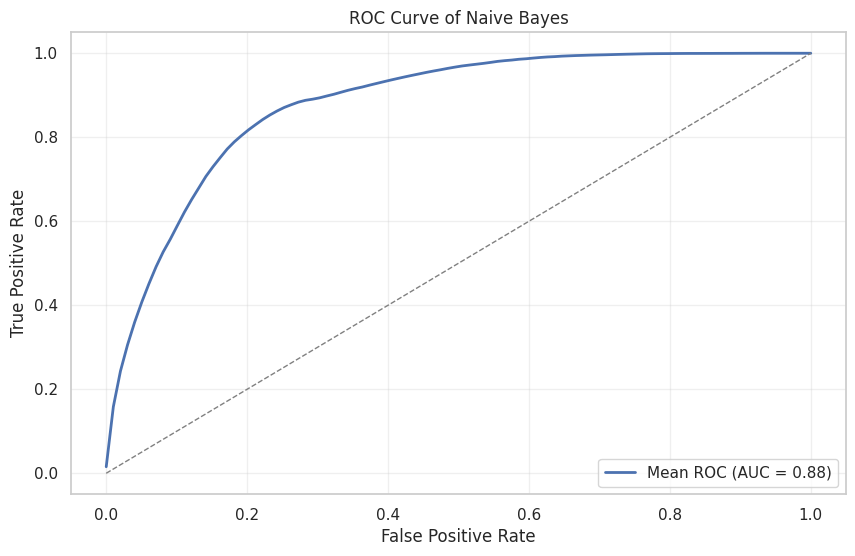

In [ ]:
plot_roc_curve(metrics["roc_data"], "Naive Bayes")

## Confusion Matrix

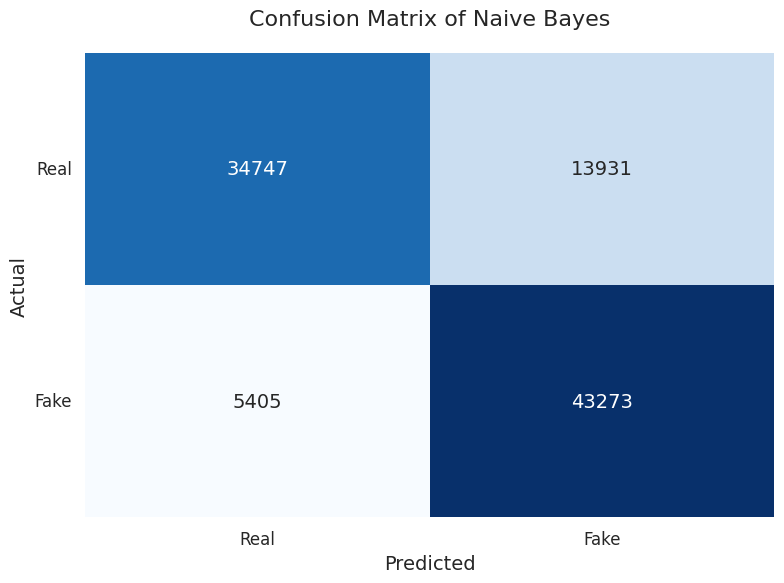

In [ ]:
plot_confusion_matrix(metrics['confusion_matrix'], "Naive Bayes")

# Comparison


In [ ]:
results_df = pd.DataFrame(results_df).sort_values(by = 'Accuracy').reset_index(drop = True)

def plot_metric_barplot(metric):
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=results_df, x="Model", y=metric, palette="viridis")

    for p in ax.patches:
        ax.annotate(
            f'{p.get_height():.2f}',
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='center', fontsize=12, color='black', xytext=(0, 5),
            textcoords='offset points'
        )

    plt.title(f"{metric}", fontsize=16, pad=15)
    plt.xlabel("Model", fontsize=14)
    plt.ylabel(metric, fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.tight_layout()

    plt.show()

## Table

In [ ]:
results_df

,Model,Accuracy,Precision,Recall,F1,AUC
0,Naive Bayes,0.801389,0.756465,0.888958,0.817374,0.879662
1,LightGBM,0.881476,0.850668,0.925414,0.886462,0.952067
2,XGBoost,0.887156,0.866178,0.915816,0.890304,0.956946
3,Random Forest,0.899955,0.881711,0.923865,0.902293,0.949827
4,CatBoost,0.900633,0.879913,0.927894,0.903265,0.964137


## Barplots

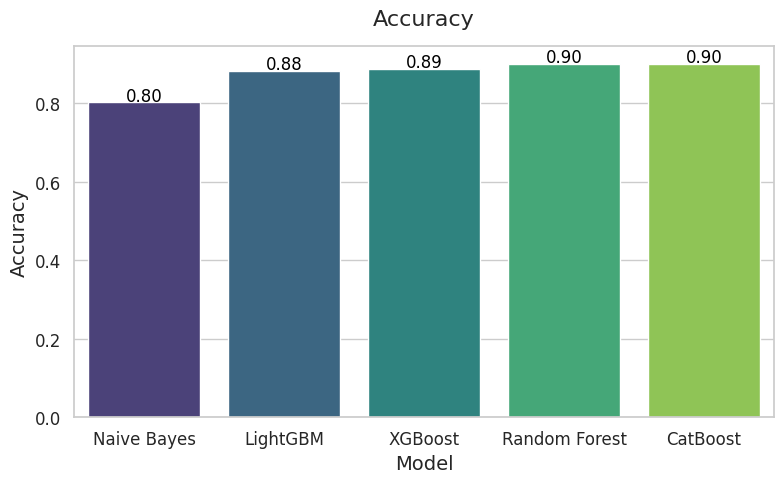

In [ ]:
plot_metric_barplot('Accuracy')

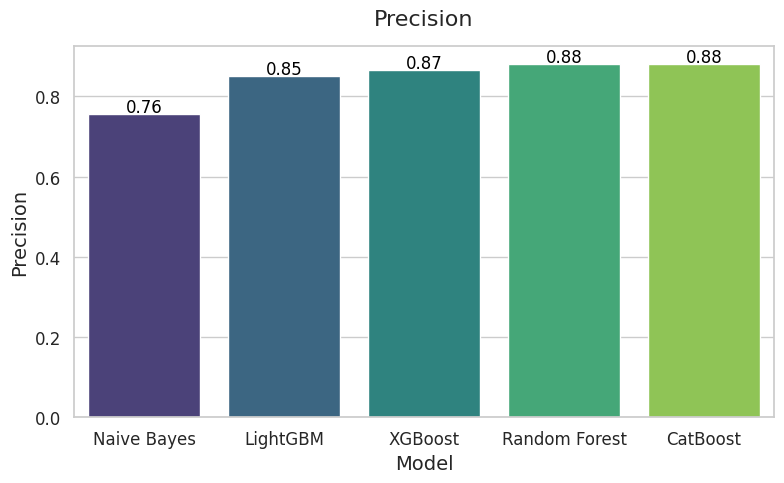

In [ ]:
plot_metric_barplot('Precision')

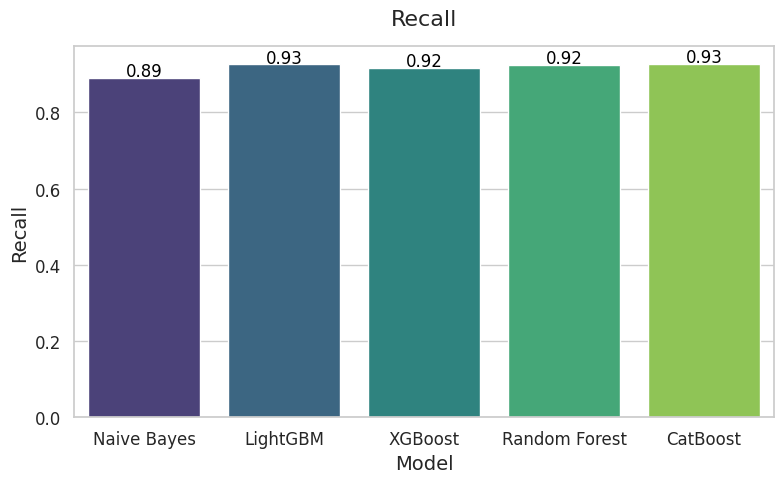

In [ ]:
plot_metric_barplot('Recall')

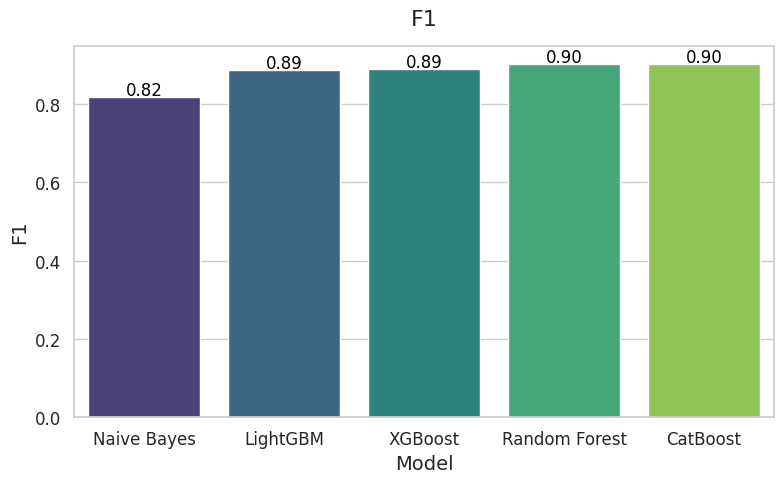

In [ ]:
plot_metric_barplot('F1')

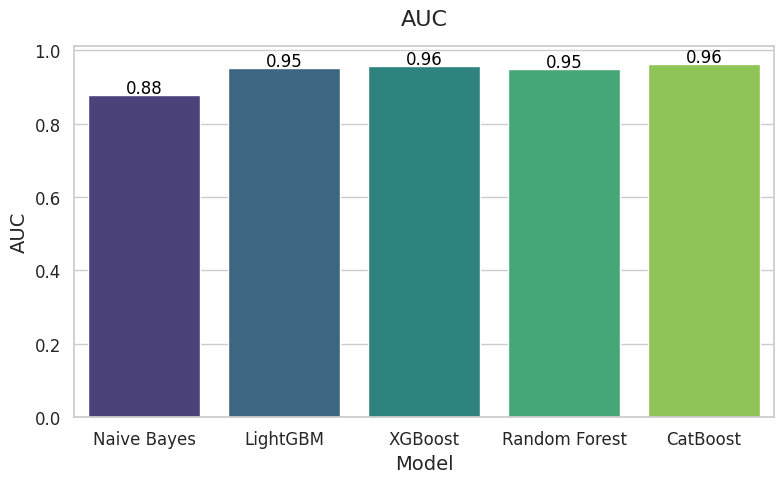

In [ ]:
plot_metric_barplot('AUC')

# Inference

## Saving Model

In [ ]:
import joblib

catboost_model = CatBoostClassifier(verbose=0)
catboost_model.fit(X, y)

joblib.dump(catboost_model, 'catboost_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

['tfidf_vectorizer.pkl']

## Inference Function

In [ ]:
loaded_model = joblib.load('catboost_model.pkl')
loaded_vectorizer = joblib.load('tfidf_vectorizer.pkl')

def predict_news(news_text):
    cleaned_text = re.sub(r'\d+', '', str(news_text))
    cleaned_text = re.sub(r'[a-zA-Z]', '', str(cleaned_text))
    cleaned_text = cleaned_text.translate(str.maketrans('', '', string.punctuation + '।'))
    cleaned_text = emoji.replace_emoji(str(cleaned_text), '')
    cleaned_text = ' '.join([word for word in str(cleaned_text).split() if word not in stop_words])
    cleaned_text = re.sub(r'\s+', ' ', str(cleaned_text)).strip()
    cleaned_text = ' '.join([stemmer.stem(word) for word in str(cleaned_text).split()])

    news_vector = loaded_vectorizer.transform([cleaned_text]).toarray()
    prediction = loaded_model.predict(news_vector)

    return "Fake" if prediction[0] == 1 else "Real"

## Example

In [ ]:
news = "বাংলাদেশের প্রধান মন্ত্রীর অসাধারণ নেতৃত্ব দেখে বিশ্ব নেতারা অবাক! তিনি একাই বদলে দিয়েছেন দেশের চিত্র।"
prediction = predict_news(news)
print(f"The news is predicted as: {prediction}")

applied fourth rules..
applied fourth rules..
applied first rules..
applied first rules..
applied second rules..
applied fourth rules..
applied fourth rules..
The news is predicted as: Real


In [ ]:
news = "গত ১৭ সেপ্টেম্বর বাংলাদেশ কৃষি বিশ্ববিদ্যালয়ে (বাকৃবি) উপাচার্যের কার্যালয়ে হট্টগোলের ঘটনায় দুইজনকে সাময়িক বরখাস্ত ও ছয় জনকে শোকজ করেছে বিশ্ববিদ্যালয় প্রশাসন। বুধবার বিশ্ববিদ্যালয় বাকৃবি রেজিস্ট্রার সাইফুল ইসলাম স্বাক্ষরিত এক নোটিশে আগামী ৭ দিনের মধ্যে উপযুক্ত উত্তর দেয়ার নির্দেশ দেয়া হয়েছে। এদিকে এ ঘটনায় আন্দোলনের সঙ্গে একাত্বতা প্রকাশ না করায় হামলার শিকার হয়ে কারিগরি কর্মচারী পরিষদের সভাপতি ও সাধারণ সম্পাদক হাসপাতালে ভর্তি হয়েছেন। সাময়িক বরখাস্তরা হলেন- শিক্ষা বিষয়ক শাখার কর্মচারী ও ৩য় শ্রেণির সাধারণ সম্পাদক মো. মোশারফ হোসেন ও কর্মকর্তা পরিষদের যুগ্ম সম্পাদক জিয়াউর রহমান টিটু। এছাড়া বিশ্ববিদ্যালয় সম্প্রসারণ কেন্দ্রের সহকারী পরিচালক মোহাম্মদ আবুল বাসার আমজাদ, ডেপুটি লাইব্রেরিয়ান মো.খাইরুল আলম নান্নু, মো.আবদুল বাতেন, ক্রীড়া প্রশিক্ষণ বিভাগের মোহাম্মদ মোস্তাইন কবীর সোহেল, সংস্থাপন শাখার সহকারী রেজিস্ট্রার মোহাম্মদ আশিকুল আলম বাচ্চু ও খামার ব্যবস্থাপনা শাখার অ্যাডিশনাল রেজিস্ট্রার ড. মো. হেলাল উদ্দীনকে কারণ দর্শানোর নোটিশ দেয় প্রশাসন।  নোটিশে উল্লেখ করা হয়, গত সোমবার দুপুরে সোয়া ১২টার দিকে উপাচার্যের অনুমতি ছাড়াই হঠাৎ করে উপাচার্যের কার্যালয়ে প্রবেশ করে ছাত্র বিষয়ক উপদেষ্টা, প্রক্টর, ডিন কাউন্সিলের আহ্বায়ক, রেজিস্ট্রার ও সাংবাদিকদের সামনে উপাচার্য ও উপ-উপাচার্যকে লক্ষ্য করে আঙ্গুল উচিয়ে কটুক্তি করে এবং অশালীন শারীরিক অঙ্গভঙ্গি করে। এতে করে বিশ্ববিদ্যালয়ের উচ্চ পর্যায়ের প্রাশাসনিক কার্যক্রম ব্যাহত হয় এবং উপাচার্যের সঙ্গে দুর্ব্যবহার করে যা বিশ্ববিদ্যালয়েল চাকরি সংবিধির সুস্পষ্ট লঙ্ঘন ও গুরুতর অপরাধ। এদিকে প্রশাসনের কারণ দর্শানোর নোটিশ পাওয়ার পর অফিসার পরিষদের নেতারা মিছিল নিয়ে হিসাব সংরক্ষণ শাখা, প্রকৌশল শাখা, পরিকল্পনা ও উন্নয়ন শাখায় তালা ঝুঁলিয়ে দেয়। তবে প্রশাসন ভবনে পুলিশ মোতায়ন থাকায় তালা দিতে ব্যর্থ হয়। কর্মকর্তাদের সঙ্গে একাত্বতা প্রকাশ করে কর্মচারীরাও ক্যাম্পাসে মিছিল করে। এসময় তারা প্রশাসনের বিরুদ্ধে বিভিন্ন ধরনে শ্লোগান দিতে থাকে।  এদিকে কারিগরি কর্মচারী পরিষদের পক্ষ থেকে আন্দোলনে সঙ্গে একাত্বতা প্রকাশ না করায় হামলা করে ৩য় ও চতুর্থ শ্রেণির কর্মচারীরা। এবিষয়ে কারিগরি কর্মচারী পরিষদের সভাপতি মো. আবদুল মোতালেব বলেন, আমরা চার দফা দাবিতে ঐক্যবদ্ধ হয়েছিলাম। গত ১৭ সেপ্টেম্বর আমাদের রেখেই ৩য় শ্রেণির সাধারণ সম্পাদক মো. মোশারফ হোসেন কর্মকর্তাদের সঙ্গে ভিসি সচিবালয়ে ঢুকে ভিসির সঙ্গে বেয়াদবি করে। পরবর্তীতে তাকে বিশ্ববিদ্যালয় থেকে শোকজ করলে আমাকে ও আমার সংগঠনের সকলকে তাদের সঙ্গে আন্দোলনে যেতে বলে। যোগ না দিলে পরে ৩য় ও ৪র্থ শ্রেণি মিলে আমাদের সংগঠনে হামলা করে, চেয়ার ভাঙে। এ ঘটনায় আমি ও আমার সংগঠনের সাধারণ সম্পাদক সুলতান আহমেদ আহত হয়ে বর্তমানে ময়মনসিংহ হাসপাতালে ভর্তি আছি। মো. শাহীন সরদার/আরএ/আরআইপি"
prediction = predict_news(news)
print(f"The news is predicted as: {prediction}")

applied second rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied second rules..
applied fourth rules..
applied first rules..
applied second rules..
applied fourth rules..
applied first rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rule